In [1]:
import pandas as pd
import numpy as np
import os
#Display all columns
pd.set_option('display.max_columns', None)


final_df = pd.read_csv(r'features_wc.csv')
final_df.head()

,nation,id,att,mid,def,fifa_rank,titles,elo_rating,copa,group,SELECOES_TOP_15,g_elo_medio,g_atk_medio,g_def_medio,g_mid_medio,g_titulos_selecao,g_med_top_percent,jogos_casa_6m,jogos_fora_6m,vitorias_6m,derrotas_6m,empates_6m,total_jogos_6m,jogos_casa_12m,jogos_fora_12m,vitorias_12m,derrotas_12m,empates_12m,total_jogos_12m,jogos_casa_18m,jogos_fora_18m,vitorias_18m,derrotas_18m,empates_18m,total_jogos_18m,jogos_casa_24m,jogos_fora_24m,vitorias_24m,derrotas_24m,empates_24m,total_jogos_24m,jogos_casa_36m,jogos_fora_36m,vitorias_36m,derrotas_36m,empates_36m,total_jogos_36m,winner
0,Iran,iran,58,69,63,23,0,1842,2006,D,0,1789.75,71.25,70.0,72.00,0.00,0.50,3.0,1.0,3.0,0.0,1.0,4.0,7.0,3.0,7.0,2.0,1.0,10.0,11.0,5.0,12.0,2.0,2.0,16.0,20.0,11.0,22.0,4.0,5.0,31.0,26,16,30,7,5,42,0
1,Japan,japan,73,71,64,18,0,1789,2006,F,0,1864.75,82.25,75.0,76.50,1.25,0.25,5.0,3.0,3.0,2.0,3.0,8.0,11.0,10.0,10.0,5.0,6.0,21.0,18.0,11.0,14.0,9.0,6.0,29.0,26.0,17.0,24.0,10.0,9.0,43.0,37,25,34,15,13,62,0
2,Saudi Arabia,saudi_arabia,60,61,60,34,0,1554,2006,H,0,1752.75,75.25,70.0,70.75,0.00,0.25,11.0,5.0,3.0,8.0,5.0,16.0,14.0,6.0,6.0,9.0,5.0,20.0,22.0,10.0,10.0,13.0,9.0,32.0,28.0,13.0,14.0,15.0,12.0,41.0,39,19,27,15,16,58,0
3,South Korea,south_korea,75,71,73,29,0,1744,2006,G,0,1750.25,79.00,73.5,72.25,0.25,0.25,4.0,6.0,6.0,2.0,2.0,10.0,12.0,8.0,10.0,4.0,6.0,20.0,17.0,12.0,14.0,7.0,8.0,29.0,26.0,15.0,21.0,9.0,11.0,41.0,36,21,29,14,14,57,0
4,Angola,angola,67,57,60,57,0,1564,2006,D,0,1789.75,71.25,70.0,72.00,0.00,0.50,3.0,5.0,3.0,3.0,2.0,8.0,8.0,9.0,7.0,5.0,5.0,17.0,8.0,12.0,8.0,7.0,5.0,20.0,12.0,16.0,12.0,7.0,9.0,28.0,17,22,18,10,11,39,0


In [24]:
final_df['copa'].unique()

array([2006, 2010, 2014, 2018, 2022, 2026])

In [2]:
final_df.tail()

,nation,id,att,mid,def,fifa_rank,titles,elo_rating,copa,group,SELECOES_TOP_15,g_elo_medio,g_atk_medio,g_def_medio,g_mid_medio,g_titulos_selecao,g_med_top_percent,jogos_casa_6m,jogos_fora_6m,vitorias_6m,derrotas_6m,empates_6m,total_jogos_6m,jogos_casa_12m,jogos_fora_12m,vitorias_12m,derrotas_12m,empates_12m,total_jogos_12m,jogos_casa_18m,jogos_fora_18m,vitorias_18m,derrotas_18m,empates_18m,total_jogos_18m,jogos_casa_24m,jogos_fora_24m,vitorias_24m,derrotas_24m,empates_24m,total_jogos_24m,jogos_casa_36m,jogos_fora_36m,vitorias_36m,derrotas_36m,empates_36m,total_jogos_36m,winner
203,Scotland,scotland,77,77,75,42,0,1782,2026,C,0,1787.00,78.25,76.50,76.50,1.25,0.50,2.0,1.0,1.0,2.0,0.0,3.0,6.0,5.0,6.0,4.0,1.0,11.0,7.0,6.0,7.0,5.0,1.0,13.0,13.0,11.0,10.0,10.0,4.0,24.0,17,17,13,15,6,34,0
204,Spain,spain,85,86,83,2,1,2157,2026,H,1,1800.75,76.50,76.00,77.00,0.75,0.25,2.0,0.0,1.0,0.0,1.0,2.0,6.0,4.0,7.0,0.0,3.0,10.0,7.0,5.0,7.0,0.0,5.0,12.0,17.0,10.0,21.0,0.0,6.0,27.0,23,14,28,1,8,37,0
205,Sweden,sweden,86,77,75,38,0,1712,2026,F,0,1798.50,78.50,76.75,77.50,0.00,0.25,1.0,1.0,2.0,0.0,0.0,2.0,5.0,5.0,4.0,4.0,2.0,10.0,6.0,6.0,5.0,5.0,2.0,12.0,10.0,10.0,10.0,7.0,3.0,20.0,16,15,16,11,4,31,0
206,Switzerland,switzerland,77,79,76,19,0,1891,2026,B,0,1673.75,75.25,72.00,72.50,0.00,0.00,2.0,1.0,1.0,1.0,1.0,3.0,5.0,6.0,7.0,1.0,3.0,11.0,6.0,7.0,8.0,1.0,4.0,13.0,12.0,14.0,11.0,5.0,10.0,26.0,16,20,14,6,16,36,0
207,Turkey,turkey,79,80,78,22,0,1911,2026,D,0,1812.00,75.00,75.00,76.25,0.00,0.00,1.0,1.0,2.0,0.0,0.0,2.0,4.0,6.0,7.0,2.0,1.0,10.0,5.0,7.0,9.0,2.0,1.0,12.0,10.0,15.0,15.0,6.0,4.0,25.0,13,22,20,9,6,35,0


In [26]:
final_df[(final_df['copa'] == 2022) & (final_df['winner'] == 1)]

,nation,id,att,mid,def,fifa_rank,titles,elo_rating,copa,group,SELECOES_TOP_15,g_elo_medio,g_atk_medio,g_def_medio,g_mid_medio,g_titulos_selecao,g_med_top_percent,jogos_casa_6m,jogos_fora_6m,vitorias_6m,derrotas_6m,empates_6m,total_jogos_6m,jogos_casa_12m,jogos_fora_12m,vitorias_12m,derrotas_12m,empates_12m,total_jogos_12m,jogos_casa_18m,jogos_fora_18m,vitorias_18m,derrotas_18m,empates_18m,total_jogos_18m,jogos_casa_24m,jogos_fora_24m,vitorias_24m,derrotas_24m,empates_24m,total_jogos_24m,jogos_casa_36m,jogos_fora_36m,vitorias_36m,derrotas_36m,empates_36m,total_jogos_36m,winner
143,Argentina,argentina,85,83,83,3,2,2143,2022,C,1,1850.0,78.75,76.75,77.0,0.5,0.5,3.0,1.0,4.0,0.0,0.0,4.0,6.0,4.0,8.0,0.0,2.0,10.0,16.0,8.0,17.0,0.0,7.0,24.0,17.0,9.0,18.0,0.0,8.0,26.0,19,11,21,0,9,30,1


In [25]:
final_df.columns

Index(['nation', 'id', 'att', 'mid', 'def', 'fifa_rank', 'titles',
       'elo_rating', 'copa', 'group', 'SELECOES_TOP_15', 'g_elo_medio',
       'g_atk_medio', 'g_def_medio', 'g_mid_medio', 'g_titulos_selecao',
       'g_med_top_percent', 'jogos_casa_6m', 'jogos_fora_6m', 'vitorias_6m',
       'derrotas_6m', 'empates_6m', 'total_jogos_6m', 'jogos_casa_12m',
       'jogos_fora_12m', 'vitorias_12m', 'derrotas_12m', 'empates_12m',
       'total_jogos_12m', 'jogos_casa_18m', 'jogos_fora_18m', 'vitorias_18m',
       'derrotas_18m', 'empates_18m', 'total_jogos_18m', 'jogos_casa_24m',
       'jogos_fora_24m', 'vitorias_24m', 'derrotas_24m', 'empates_24m',
       'total_jogos_24m', 'jogos_casa_36m', 'jogos_fora_36m', 'vitorias_36m',
       'derrotas_36m', 'empates_36m', 'total_jogos_36m', 'winner'],
      dtype='object')

In [3]:
COLUNAS_ID = ['nation', 'id', 'copa', 'group']
COLUNA_TARGET = ['winner']
COLUNAS_FEATURES = ['att', 'mid', 'def', 'fifa_rank', 'titles',
       'elo_rating', 'SELECOES_TOP_15', 'g_elo_medio',
       'g_atk_medio', 'g_def_medio', 'g_mid_medio', 'g_titulos_selecao',
       'g_med_top_percent', 'jogos_casa_6m', 'jogos_fora_6m', 'vitorias_6m',
       'derrotas_6m', 'empates_6m', 'total_jogos_6m', 'jogos_casa_12m',
       'jogos_fora_12m', 'vitorias_12m', 'derrotas_12m', 'empates_12m',
       'total_jogos_12m', 'jogos_casa_18m', 'jogos_fora_18m', 'vitorias_18m',
       'derrotas_18m', 'empates_18m', 'total_jogos_18m', 'jogos_casa_24m',
       'jogos_fora_24m', 'vitorias_24m', 'derrotas_24m', 'empates_24m',
       'total_jogos_24m', 'jogos_casa_36m', 'jogos_fora_36m', 'vitorias_36m',
       'derrotas_36m', 'empates_36m', 'total_jogos_36m']

In [11]:
df_train = final_df[final_df['copa'] < 2026] # Dataframe de treino
print(f"Quantidade de copas no dataframe de treino: {df_train['copa'].nunique()}")
print(f"Copas do dataframe de treino: {df_train['copa'].unique()}")

Quantidade de copas no dataframe de treino: 5
Copas do dataframe de treino: [2006 2010 2014 2018 2022]


- o Recall é a porcentagem de campeões reais que o modelo conseguiu encontrar
- Precisão é a taxa de acerto entre aqueles que ele afirmou ser campeões
- F1-Score é a nota que equilibra ambas para evitar tanto o excesso de alarmes falsos quanto a perda de campeões verdadeiros

=== Avaliação dos Modelos — Average Precision (Base de Teste) ===

Logistic Regression: 1.0000
Random Forest: 0.0000
Gradient Boosting: 0.0000
Extra Trees: 0.0000
SVM: 0.0000
MLP (Neural Network): 0.0000
AdaBoost: 0.0000

🏆 Melhor modelo: Logistic Regression  (Avg Precision no Teste: 1.0000)
------------------------------------------------------------

[ TREINO ] - Relatório de Classificação: Logistic Regression
              precision    recall  f1-score   support

           0       1.00      0.92      0.96       108
           1       0.31      1.00      0.47         4

    accuracy                           0.92       112
   macro avg       0.65      0.96      0.71       112
weighted avg       0.98      0.92      0.94       112


[ TESTE ] - Relatório de Classificação: Logistic Regression
              precision    recall  f1-score   support

           0       1.00      0.83      0.91        47
           1       0.11      1.00      0.20         1

    accuracy                    

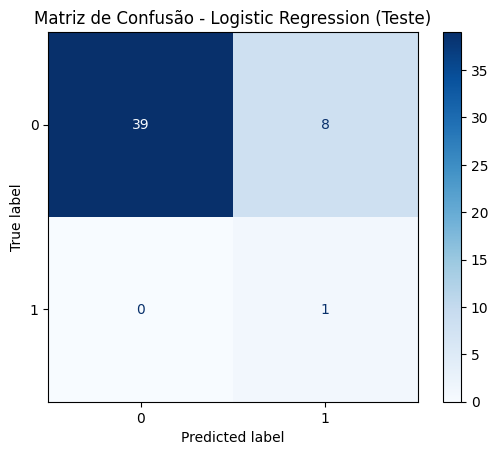

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, 
    ExtraTreesClassifier, AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, 
    average_precision_score, 
    recall_score,
    ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings('ignore')

# Peso personalizado: muito menos agressivo que 'balanced' (~168:1)
# Favorece o campeão sem gerar falsos positivos em excesso
cw = {0: 1, 1: 150}

# --- Modelos com Parametrizações Contra Overfitting ---
models = {
    'Logistic Regression': LogisticRegression(
        class_weight=cw, max_iter=1000, C=0.05, random_state=42 # C reduzido (maior regularização L2)
    ),
    
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight=cw, max_depth=4, 
        min_samples_leaf=5, max_samples=0.8, random_state=42 # min_samples_leaf aumentado, limitando uso total das amostras (max_samples)
    ),
    
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=50, max_depth=3, min_samples_leaf=5, 
        learning_rate=0.05, subsample=0.8, random_state=42 # min_samples_leaf adicionado
    ),
    
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200, class_weight=cw, max_depth=4, 
        min_samples_leaf=5, bootstrap=True, max_samples=0.8, random_state=42 # bootstrap e max_samples ativados
    ),
    
    'SVM': SVC(
        class_weight=cw, probability=True, kernel='rbf', 
        C=0.5, random_state=42 # C reduzido para aceitar uma margem mais suave (soft margin)
    ),
    
    'MLP (Neural Network)': MLPClassifier(
        hidden_layer_sizes=(32, 16), alpha=0.1, 
        early_stopping=True, max_iter=500, random_state=42 # alpha mais forte (L2) e parada antecipada
    ),
    
    'AdaBoost': AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=42 # Learning rate conservadora
    )
}

def make_pipe(model):
    return Pipeline([('scaler', StandardScaler()), ('clf', model)])

# Preparação dos dados
# Certifique-se de que df_train, COLUNAS_FEATURES e COLUNA_TARGET já estão definidos antes desse bloco
X = df_train[COLUNAS_FEATURES]
y = df_train[COLUNA_TARGET].values.ravel()

# --- Train/Test Split Estratificado ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, # 30% dos dados para teste
    stratify=y,    # Estratificação pela classe campeão
    random_state=42
)

print("=== Avaliação dos Modelos — Average Precision (Base de Teste) ===\n")
test_scores = {}
fitted_models = {}

for name, model in models.items():
    pipe = make_pipe(model)
    pipe.fit(X_train, y_train)
    
    # Extrair probabilidades para cálculo do Average Precision
    if hasattr(pipe, "predict_proba"):
        y_test_probs = pipe.predict_proba(X_test)[:, 1]
    else:
        y_test_probs = pipe.decision_function(X_test)
        
    # score = average_precision_score(y_test, y_test_probs)
    # Calcular o Recall apenas para a classe 1
    y_pred_test = pipe.predict(X_test)
    score = recall_score(y_test, y_pred_test, pos_label=1)
    test_scores[name] = score
    fitted_models[name] = pipe # Salvando o modelo treinado
    
    print(f"{name}: {score:.4f}")

# --- Seleção do Campeão ---
best_name = max(test_scores, key=test_scores.get)
print(f"\n🏆 Melhor modelo: {best_name}  (Avg Precision no Teste: {test_scores[best_name]:.4f})")
print("-" * 60)

best_model = fitted_models[best_name]

# --- Classification Reports ---
print(f"\n[ TREINO ] - Relatório de Classificação: {best_name}")
y_pred_train = best_model.predict(X_train)
print(classification_report(y_train, y_pred_train))

print(f"\n[ TESTE ] - Relatório de Classificação: {best_name}")
y_pred_test = best_model.predict(X_test)
print(classification_report(y_test, y_pred_test))

# --- Matriz de Confusão ---
print("\nGerando Matriz de Confusão para a Base de Teste...")
ConfusionMatrixDisplay.from_estimator(
    best_model, 
    X_test, 
    y_test, 
    cmap='Blues',
    values_format='d'
)
plt.title(f"Matriz de Confusão - {best_name} (Teste)")
plt.show();

In [30]:
# Prever probabilidades por copa
COPA = 2026
X_inf = final_df[final_df['copa'] == COPA][COLUNAS_FEATURES]

probabilities = best_model.predict_proba(X_inf)[:, 1]  # Probabilidade de ser campeão (classe 1)

df_inf = final_df[final_df['copa'] == COPA].copy()
df_inf['probabilidade_campeao'] = probabilities
df_inf[['nation', 'copa', 'probabilidade_campeao']].sort_values(by='probabilidade_campeao', ascending=False).reset_index(drop=True)

,nation,copa,probabilidade_campeao
0,France,2026,0.901979
1,Spain,2026,0.868200
2,Argentina,2026,0.729733
3,Portugal,2026,0.665446
4,England,2026,0.439313
5,Netherlands,2026,0.318139
6,Senegal,2026,0.317532
7,Brazil,2026,0.312354
8,Croatia,2026,0.189577
9,Japan,2026,0.156757
